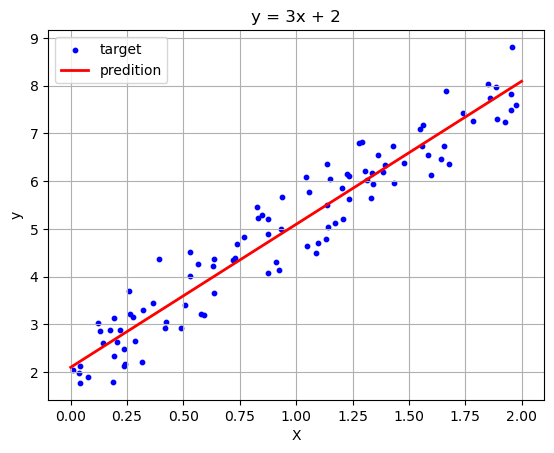

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
np.random.seed(0)
X = 2 * np.random.rand(100, 1)  # 生成100个随机点
y = 3 * X.flatten() + 2 + np.random.randn(100) * 0.5  # y = 3x + 2 加入噪声

# 将数据分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression
# 创建线性回归模型
model = LinearRegression()
# 训练模型
model.fit(X_train, y_train)

# 进行预测
y_pred = model.predict(X_test)

from sklearn.metrics import mean_squared_error, r2_score
# 计算性能指标
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

import matplotlib.pyplot as plt
# 原始数据与预测值的可视化
plt.scatter(X, y, color='blue', label='target', s=10)
X_line = np.linspace(0, 2, 100).reshape(-1, 1)  # 创建用于绘制回归线的X值
y_line = model.predict(X_line)
plt.plot(X_line, y_line, color='red', linewidth=2, label='predition')
plt.xlabel('X')
plt.ylabel('y')
plt.title("y = 3x + 2")
plt.legend()
plt.grid()

缺失值统计:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

模型性能:
均方误差 (MSE): 0.5559
决定系数 (R^2): 0.5758


C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25151 (\N{CJK UNIFIED IDEOGRAPH-623F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20215 (\N{CJK UNIFIED IDEOGRAPH-4EF7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  

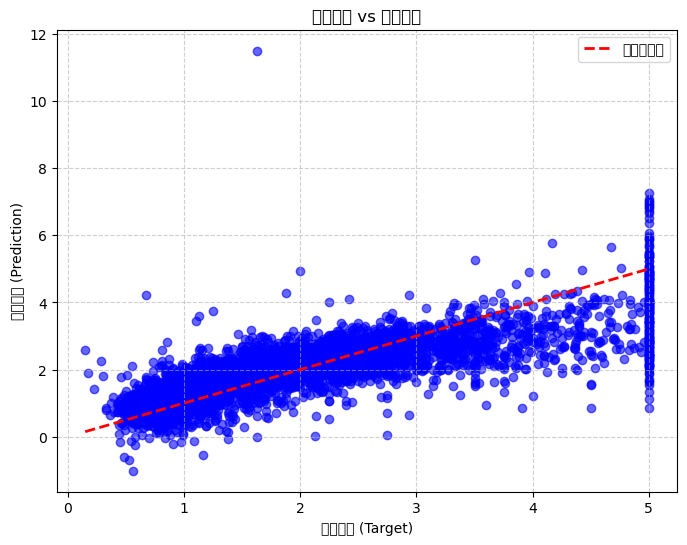

In [6]:
from sklearn.datasets import fetch_california_housing  # Removed parentheses from import
import pandas as pd

# 加载数据集
try:
    cal = fetch_california_housing()
except Exception as e:
    print(f"下载数据集失败，尝试本地加载: {e}")
    # 示例路径，请替换为实际路径
    # 注意：路径中的反斜杠需要双写或使用原始字符串
    local_path = "D:\\Code\\cal_housing_py3.pkz"  # 替换为你的实际路径
    cal = fetch_california_housing(data_home=local_path, download_if_missing=False)

# 得到样本特征与样本目标值
X = pd.DataFrame(cal.data, columns=cal.feature_names)
y = cal.target

from sklearn.model_selection import train_test_split

# 检查缺失值
print("缺失值统计:")
print(X.isnull().sum())

# 划分数据集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression

# 创建模型
model = LinearRegression()

# 训练模型
model.fit(X_train, y_train)

from sklearn.metrics import mean_squared_error, r2_score

# 进行预测
y_pred = model.predict(X_test)

# 计算性能指标
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# 打印性能指标
print('\n模型性能:')
print(f'均方误差 (MSE): {mse:.4f}')  # 保留4位小数
print(f'决定系数 (R^2): {r2:.4f}')   # 保留4位小数

import matplotlib.pyplot as plt

# 可视化预测结果
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6)
plt.xlabel('实际房价 (Target)')
plt.ylabel('预测房价 (Prediction)')
plt.title('实际房价 vs 预测房价')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 
         color='red', linewidth=2, linestyle='--', label='理想预测线')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [8]:
# 乳腺癌检测 - 逻辑回归模型

# 导入所需库
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import pandas as pd

# 1. 加载数据集
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# 2. 数据观察与预处理
# 查看数据基本信息
print("特征形状:", X.shape)
print("前5行数据:\n", X.head())
print("目标值分布:\n", pd.Series(y).value_counts())

# 数据标准化
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. 划分数据集
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=3149)

# 4. 创建并训练模型
# 设置超参数：正则化强度C=1.0，使用l2正则化
model = LogisticRegression(C=1.0, penalty='l2', solver='liblinear', random_state=3149)
model.fit(X_train, y_train)

# 5. 预测与评估
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# 6. 输出结果
print("\n模型评估结果:")
print(f"测试集准确率: {accuracy:.4f}")

# 7. 特征重要性分析
importance = pd.DataFrame({
    '特征': data.feature_names,
    '系数绝对值': abs(model.coef_[0])
}).sort_values('系数绝对值', ascending=False)

print("\n特征重要性排序(前10):")
print(importance.head(10))

特征形状: (569, 30)
前5行数据:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst p

In [ ]:
通过特征重要性分析，发现“worst concave points”和“mean concave points”等特征对预测结果影响最大，所以适当调整正则化参数可以防止过拟合，提高模型泛化能力